In [6]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import glob


In [8]:
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB, ComplementNB
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, accuracy_score


In [10]:
files = glob.glob('*.csv')
files

['Youtube01.csv',
 'Youtube02.csv',
 'Youtube03.csv',
 'Youtube04.csv',
 'Youtube05.csv']

In [11]:
all_df =[]
for file in files:
    all_df.append(pd.read_csv(file).drop(['COMMENT_ID','AUTHOR','DATE'], axis=1))
len(all_df)

5

In [12]:
all_df[0]

,CONTENT,CLASS
0,"Huh, anyway check out this you[tube] channel: ...",1
1,Hey guys check out my new channel and our firs...,1
2,just for test I have to say murdev.com,1
3,watch?v=vtaRGgvGtWQ Check this out .﻿,1
4,"Hey, check out my new website!! This site is a...",1
...,...,...
344,How can this have 2 billion views when there's...,0
345,I don't now why I'm watching this in 2014﻿,0
346,subscribe to me for call of duty vids and give...,1
347,hi guys please my android photo editor downloa...,1


In [13]:
df = pd.concat(all_df, axis=0, ignore_index=True)
df.head()

,CONTENT,CLASS
0,"Huh, anyway check out this you[tube] channel: ...",1
1,Hey guys check out my new channel and our firs...,1
2,just for test I have to say murdev.com,1
3,watch?v=vtaRGgvGtWQ Check this out .﻿,1
4,"Hey, check out my new website!! This site is a...",1


In [14]:
print(f'Data size: {df.shape[0]}, Number of features: {df.shape[1]}')
print(f'No of nulls: {df.isnull().sum().sum()}, No of duplicates: {df.duplicated().sum()}')

Data size: 1955, Number of features: 2
No of nulls: 0, No of duplicates: 196


In [15]:
df['CLASS'].value_counts()


CLASS
1    1004
0     951
Name: count, dtype: int64

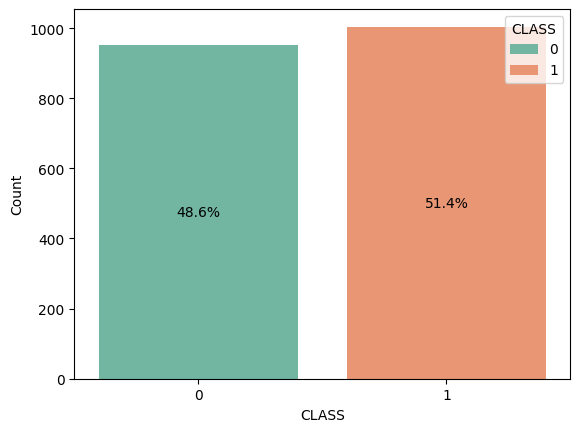

In [17]:
ax = sns.countplot(data=df, x='CLASS', hue='CLASS', palette='Set2')

total = len(df)
for bar in ax.patches:
    height = bar.get_height()
    if height > 0:
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            height / 2,
            f'{height / total:.1%}',
            ha='center',
            va='center'
        )

ax.set_ylabel('Count')
plt.show()

In [21]:
toy_vec = CountVectorizer()
text1= ["this is a sample text",]
toy_vec.fit(text1).get_feature_names_out()
toy_vec.transform(text1).toarray()

array([[1, 1, 1, 1]])

In [23]:
text2 = ["this is another sample sample text",]
toy_vec.transform(text2).toarray()

array([[1, 2, 1, 1]])

In [24]:
X = df['CONTENT']
y = df['CLASS']
x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.2,stratify=y, random_state=42)


In [25]:
x_train.shape

(1564,)

In [26]:
vectorizer = CountVectorizer()
x_train_vec = vectorizer.fit_transform(x_train)
x_test_vec = vectorizer.transform(x_test)


In [27]:
x_train_vec.shape, x_test_vec.shape

((1564, 3905), (391, 3905))

In [28]:
x_test_vec.shape

(391, 3905)

In [29]:
clf = MultinomialNB()
clf.fit(x_train_vec, y_train)
y_pred = clf.predict(x_test_vec)
print(classification_report(y_test, y_pred, target_names=['ham', 'spam']))

              precision    recall  f1-score   support

         ham       0.95      0.85      0.90       190
        spam       0.87      0.96      0.91       201

    accuracy                           0.91       391
   macro avg       0.91      0.90      0.90       391
weighted avg       0.91      0.91      0.90       391



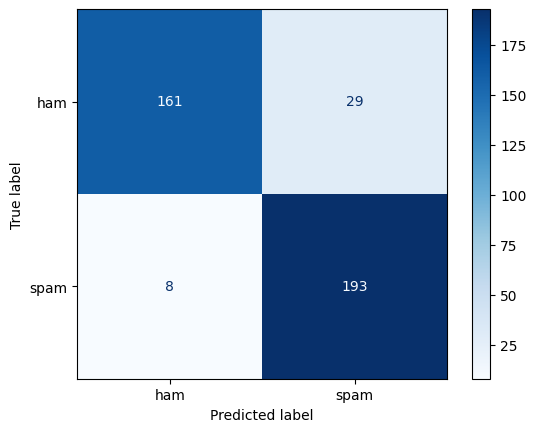

In [31]:
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=['ham', 'spam'], cmap='Blues')
plt.show()

In [33]:
example_text = ["click here to win a free iPhone",
                 "this is a normal comment",
                   "buy cheap products now", 
                   "I love this video!",
                   "subscribe to my channel for more content",
                   "while this is a normal comment, click here to win a free iPhone",
                   "this is a normal comment, but buy cheap products now",]

x_example_vec = vectorizer.transform(example_text)

y_pred_example = clf.predict(x_example_vec)
y_pred_example_proba = clf.predict_proba(x_example_vec)

for text, prediction, probabilities in zip(
    example_text, y_pred_example, y_pred_example_proba
):
    confidence = probabilities.max()
    label = "spam" if prediction == 1 else "ham"
    print(f"{label} ({confidence:.2%} confidence): {text}")
print(y_pred_example)

                

spam (99.95% confidence): click here to win a free iPhone
ham (55.07% confidence): this is a normal comment
spam (67.82% confidence): buy cheap products now
ham (85.07% confidence): I love this video!
spam (100.00% confidence): subscribe to my channel for more content
spam (99.81% confidence): while this is a normal comment, click here to win a free iPhone
spam (66.09% confidence): this is a normal comment, but buy cheap products now
[1 0 1 0 1 1 1]
